In [42]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Data Understanding

In [30]:
# Import Dataset
df = pd.read_csv('boston.csv')

# Preview Dataset
df.sample(10)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
18,0.80271,0.0,8.14,0,0.538,5.456,36.6,3.7965,4,307,21.0,288.99,11.69,20.2
57,0.01432,100.0,1.32,0,0.411,6.816,40.5,8.3248,5,256,15.1,392.90,3.95,31.6
195,0.01381,80.0,0.46,0,0.422,7.875,32.0,5.6484,4,255,14.4,394.23,2.97,50.0
157,1.22358,0.0,19.58,0,0.605,6.943,97.4,1.8773,5,403,14.7,363.43,4.59,41.3
92,0.04203,28.0,15.04,0,0.464,6.442,53.6,3.6659,4,270,18.2,395.01,8.16,22.9
385,16.81180,0.0,18.10,0,0.700,5.277,98.1,1.4261,24,666,20.2,396.90,30.81,7.2
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
254,0.04819,80.0,3.64,0,0.392,6.108,32.0,9.2203,1,315,16.4,392.89,6.57,21.9
458,7.75223,0.0,18.10,0,0.713,6.301,83.7,2.7831,24,666,20.2,272.21,16.23,14.9
144,2.77974,0.0,19.58,0,0.871,4.903,97.8,1.3459,5,403,14.7,396.90,29.29,11.8


In [31]:
# Identifikasi Ukuran Dataset
print(f"\n Ukuran Dataset: {df.shape}")
print(f"   Baris: {df.shape[0]}")
print(f"   Kolom: {df.shape[1]}")


 Ukuran Dataset: (506, 14)
   Baris: 506
   Kolom: 14


In [32]:
# Identifikasi Tipe Data Pada Setiap Kolom Dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [33]:
# Menentukan Feature dan Target
feature = df.drop(columns='medv')
target = df[['medv']]

# Split Dataset: 80% Data Pretrain & 20% Data Test
X_pretrain, X_test, y_pretrain, y_test = train_test_split(feature, target, test_size=0.2, random_state=42)

# Split Data Pretrain: 60% Data Training & 20% Data Validation
X_train, X_val, y_train, y_val = train_test_split(X_pretrain, y_pretrain, test_size=0.2, random_state=42)

# Identifikasi Ukuran Data Training, Validation, dan Testing
print(f"\n Ukuran Data Training: {X_train.shape}")
print(f" Ukuran Data Validation: {X_val.shape}")
print(f" Ukuran Data Testing   : {X_test.shape}")


 Ukuran Data Training: (323, 13)
 Ukuran Data Validation: (81, 13)
 Ukuran Data Testing   : (102, 13)


# Data Preprocessing

In [34]:
# Menggabungkan Feature dan Target Data Training untuk Data Preprocessing
train_data = pd.concat([X_train, y_train], axis=1)

## Duplicate Rows Check

In [35]:
# Identifikasi Duplicate Rows pada Data Training
print(f"\n Jumlah Duplicate Rows: {train_data.duplicated().sum()}")


 Jumlah Duplicate Rows: 0


## Missing Values Check

In [36]:
# Identifikasi Missing Values pada Data Training
print("\n Jumlah Missing Values:")
missing_count = train_data.isnull().sum()
print(missing_count[missing_count > 0])

# Identifikasi Persentase Missing Values pada Data Training
print("\n Persentase Missing Values:")
missing_pct = (train_data.isnull().sum() / len(train_data) * 100).round(2)
missing_summary = pd.DataFrame({
    'Jumlah': missing_count,
    'Persentase': missing_pct
})
print(missing_summary[missing_summary['Jumlah'] > 0].sort_values('Persentase', ascending=False))


 Jumlah Missing Values:
Series([], dtype: int64)

 Persentase Missing Values:
Empty DataFrame
Columns: [Jumlah, Persentase]
Index: []


## Outlier Check


=== Visualisasi Sebelum Penanganan Outlier (Data Train) ===


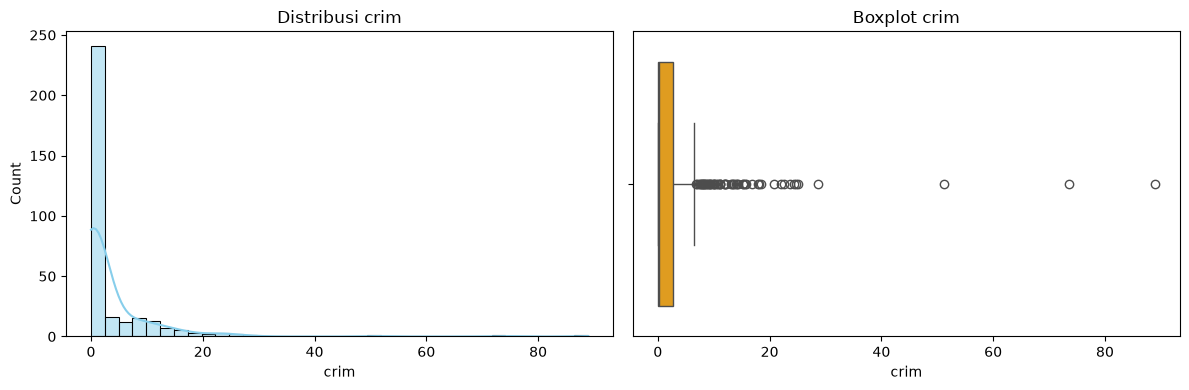

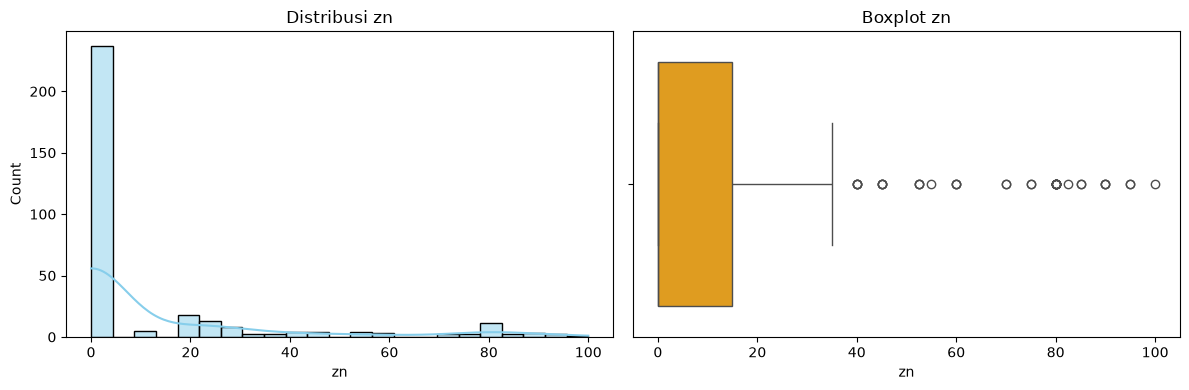

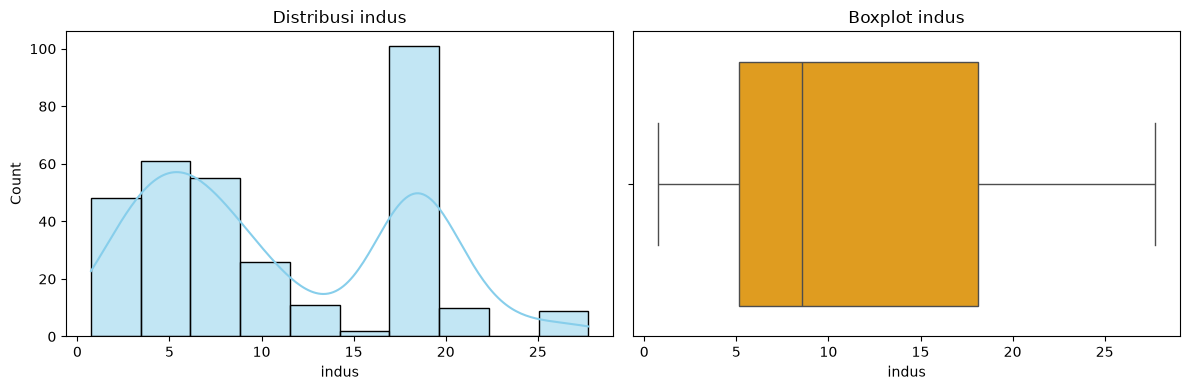

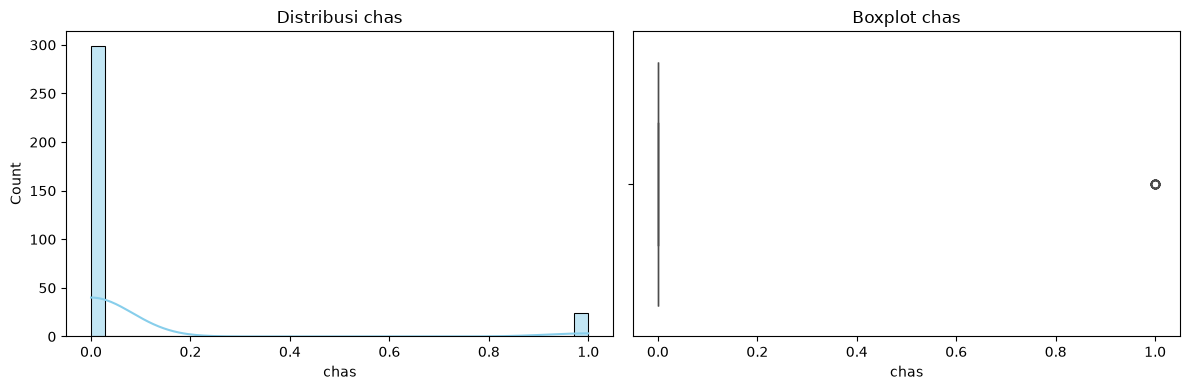

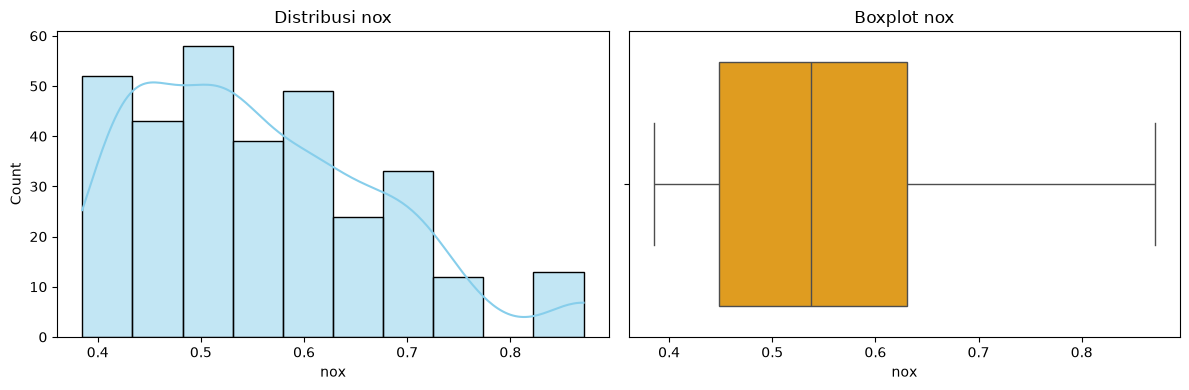

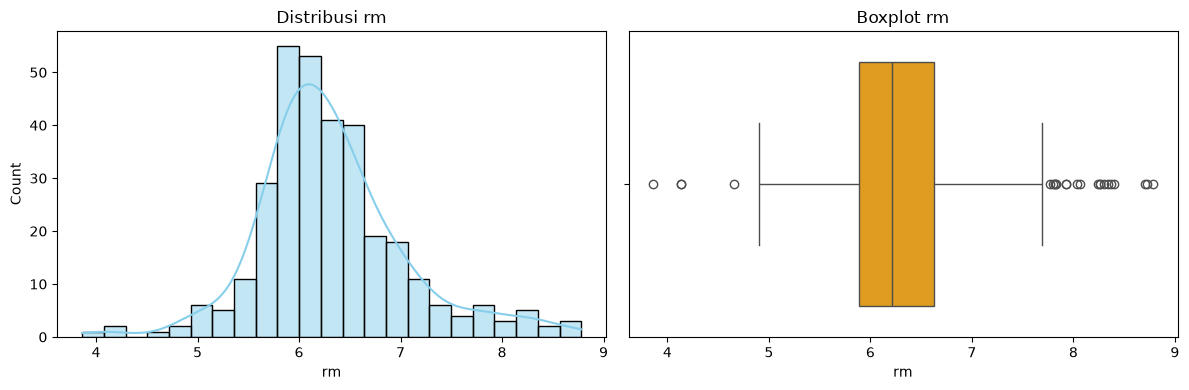

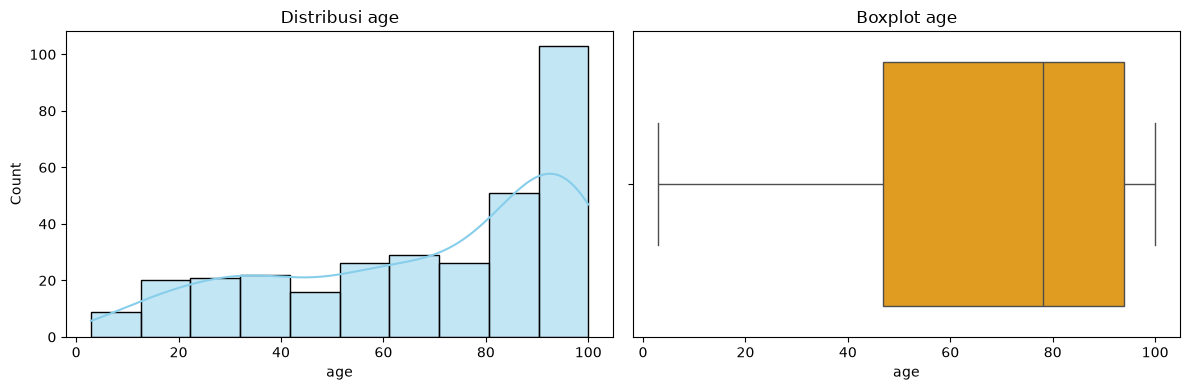

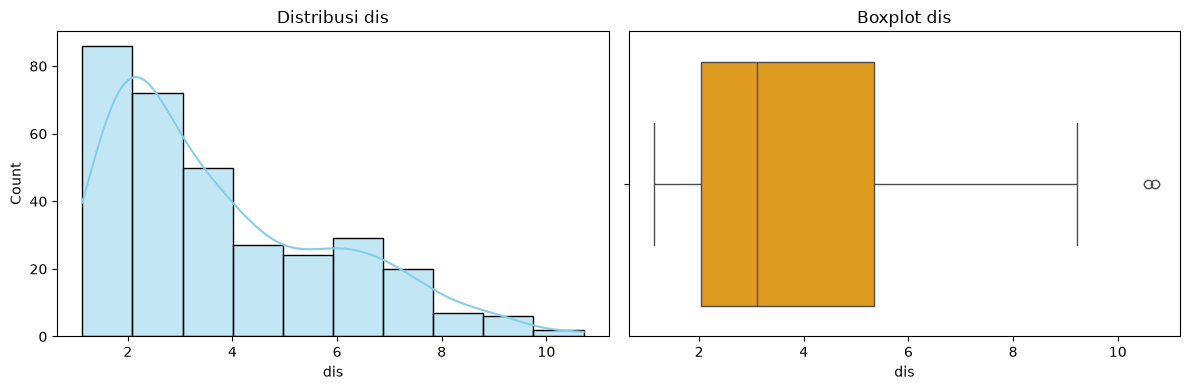

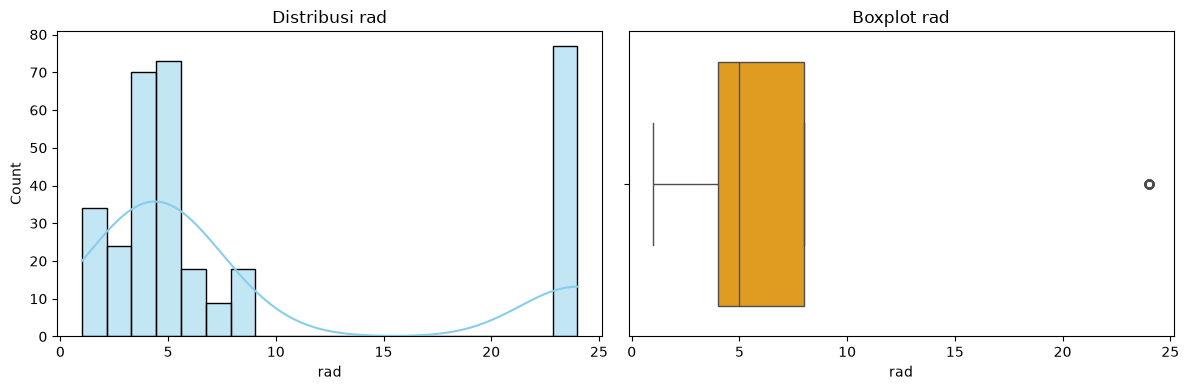

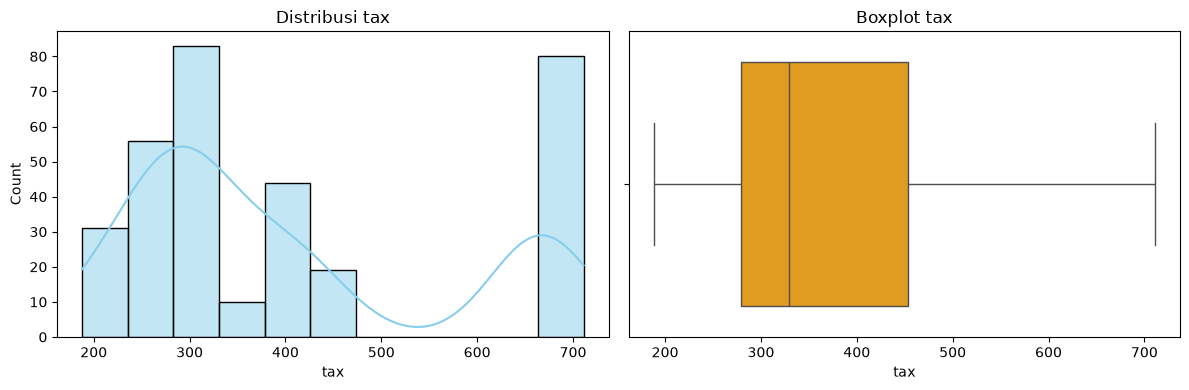

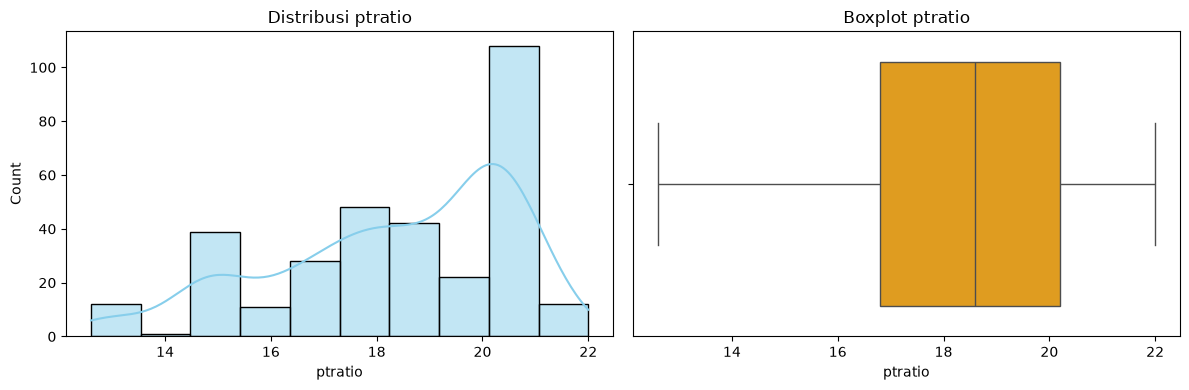

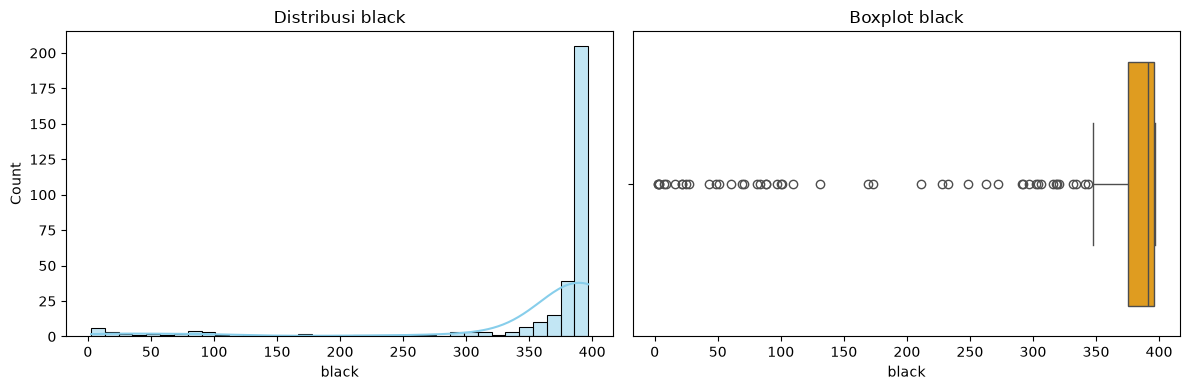

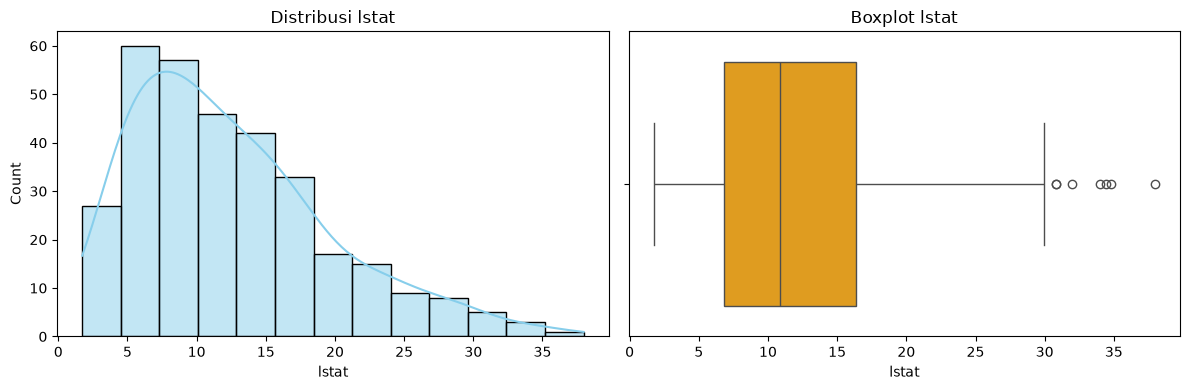

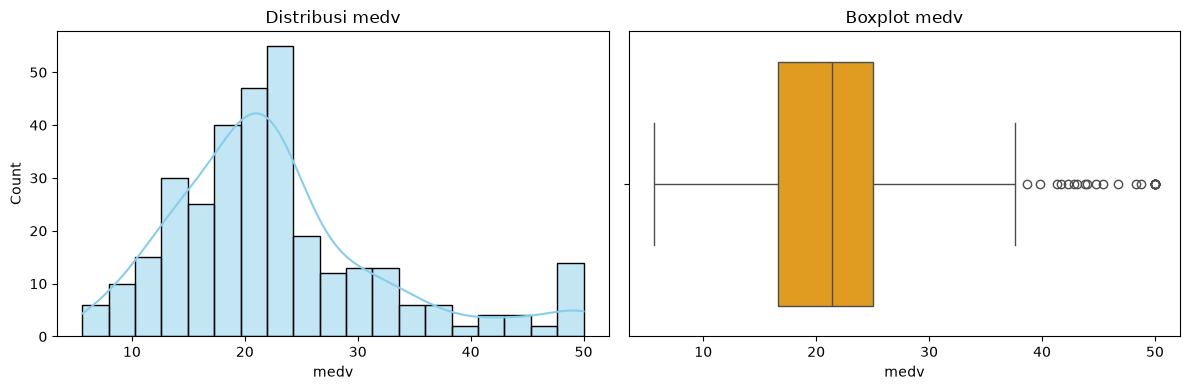

In [37]:
# Membuat Function Visualisasi Distribusi Data
def plot_distribution_outlier(data, kolom):

  fig, axes = plt.subplots(1, 2, figsize=(12, 4))

  # Plot distribusi
  sns.histplot(data[kolom], kde=True, ax=axes[0], color="skyblue")
  axes[0].set_title(f'Distribusi {kolom}')

  # Boxplot untuk outlier
  sns.boxplot(x=data[kolom], ax=axes[1], color="orange")
  axes[1].set_title(f'Boxplot {kolom}')

  plt.tight_layout()
  plt.show()

# Menampilkan Visualisasi Distribusi Data untuk Setiap Kolom pada Data Training Sebelum Penanganan Outlier
print("\n=== Visualisasi Sebelum Penanganan Outlier (Data Train) ===")
for kolom in train_data.columns:
    plot_distribution_outlier(train_data, kolom)

In [38]:
# Membuat Salinan Dataframe agar Tidak Mengganggu Dataframe Asli
df_non_outlier = train_data.copy()

# Menghitung Z-Score untuk Setiap Kolom Pada Data Training
for kolom in train_data.columns:
     df_non_outlier[f'Z_Score_{kolom}'] = stats.zscore(df_non_outlier[kolom])

# Identifikasi "df_non_outlier" Setelah Perhitungan Z-Score
df_non_outlier.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'black', 'lstat', 'medv', 'Z_Score_crim', 'Z_Score_zn',
       'Z_Score_indus', 'Z_Score_chas', 'Z_Score_nox', 'Z_Score_rm',
       'Z_Score_age', 'Z_Score_dis', 'Z_Score_rad', 'Z_Score_tax',
       'Z_Score_ptratio', 'Z_Score_black', 'Z_Score_lstat', 'Z_Score_medv'],
      dtype='str')

In [39]:
# Menghitung Jumlah Data yang Bernilai Dibawah -3 atau Diatas 3
kolom_zscore = ['Z_Score_crim', 'Z_Score_zn',
       'Z_Score_indus', 'Z_Score_chas', 'Z_Score_nox', 'Z_Score_rm',
       'Z_Score_age', 'Z_Score_dis', 'Z_Score_rad', 'Z_Score_tax',
       'Z_Score_ptratio', 'Z_Score_black', 'Z_Score_lstat', 'Z_Score_medv']

for kolom in kolom_zscore:
    jumlah_outlier = ((df_non_outlier[kolom] < -3) | (df_non_outlier[kolom] > 3)).sum()
    print(f"Jumlah outlier pada {kolom}: {jumlah_outlier}")

Jumlah outlier pada Z_Score_crim: 3
Jumlah outlier pada Z_Score_zn: 9
Jumlah outlier pada Z_Score_indus: 0
Jumlah outlier pada Z_Score_chas: 24
Jumlah outlier pada Z_Score_nox: 0
Jumlah outlier pada Z_Score_rm: 4
Jumlah outlier pada Z_Score_age: 0
Jumlah outlier pada Z_Score_dis: 2
Jumlah outlier pada Z_Score_rad: 0
Jumlah outlier pada Z_Score_tax: 0
Jumlah outlier pada Z_Score_ptratio: 0
Jumlah outlier pada Z_Score_black: 15
Jumlah outlier pada Z_Score_lstat: 4
Jumlah outlier pada Z_Score_medv: 0


In [40]:
# Menghitung IQR untuk Setiap Kolom Pada Data Training
for kolom in train_data.columns:
    IQR = df_non_outlier[kolom].quantile(0.75) - df_non_outlier[kolom].quantile(0.25)
    lower_boundary = df_non_outlier[kolom].quantile(0.25) - (IQR * 1.5)
    upper_boundary = df_non_outlier[kolom].quantile(0.75) + (IQR * 1.5)

    print(f"Kolom: {kolom}")
    print(f"Lower Boundary: {lower_boundary:.3f}")
    print(f"Upper Boundary: {upper_boundary:.3f}")
    print()

Kolom: crim
Lower Boundary: -3.826
Upper Boundary: 6.591

Kolom: zn
Lower Boundary: -22.500
Upper Boundary: 37.500

Kolom: indus
Lower Boundary: -14.250
Upper Boundary: 37.510

Kolom: chas
Lower Boundary: 0.000
Upper Boundary: 0.000

Kolom: nox
Lower Boundary: 0.175
Upper Boundary: 0.905

Kolom: rm
Lower Boundary: 4.774
Upper Boundary: 7.744

Kolom: age
Lower Boundary: -23.550
Upper Boundary: 164.450

Kolom: dis
Lower Boundary: -2.938
Upper Boundary: 10.313

Kolom: rad
Lower Boundary: -2.000
Upper Boundary: 14.000

Kolom: tax
Lower Boundary: 18.000
Upper Boundary: 714.000

Kolom: ptratio
Lower Boundary: 11.700
Upper Boundary: 25.300

Kolom: black
Lower Boundary: 344.910
Upper Boundary: 427.070

Kolom: lstat
Lower Boundary: -7.530
Upper Boundary: 30.750

Kolom: medv
Lower Boundary: 4.050
Upper Boundary: 37.650



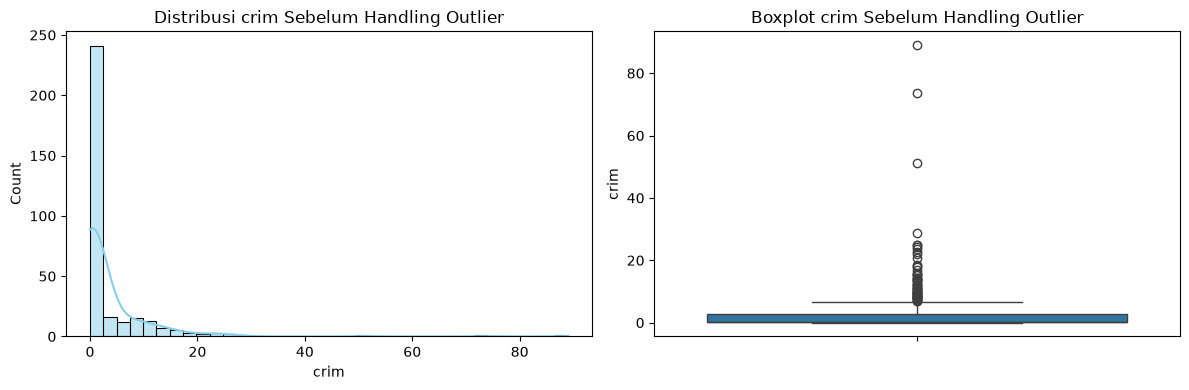

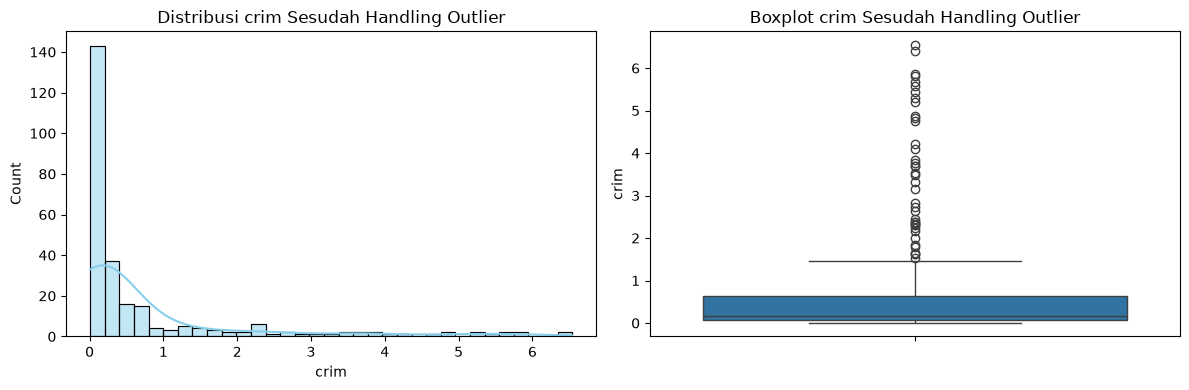

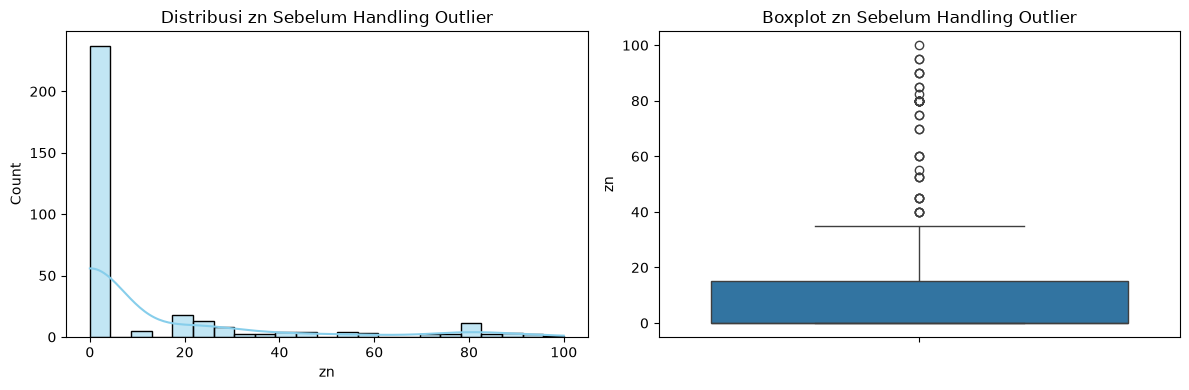

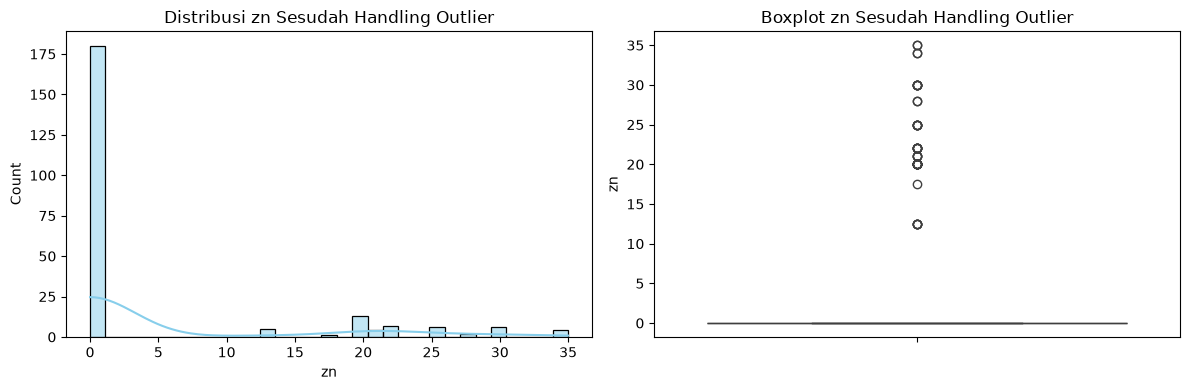

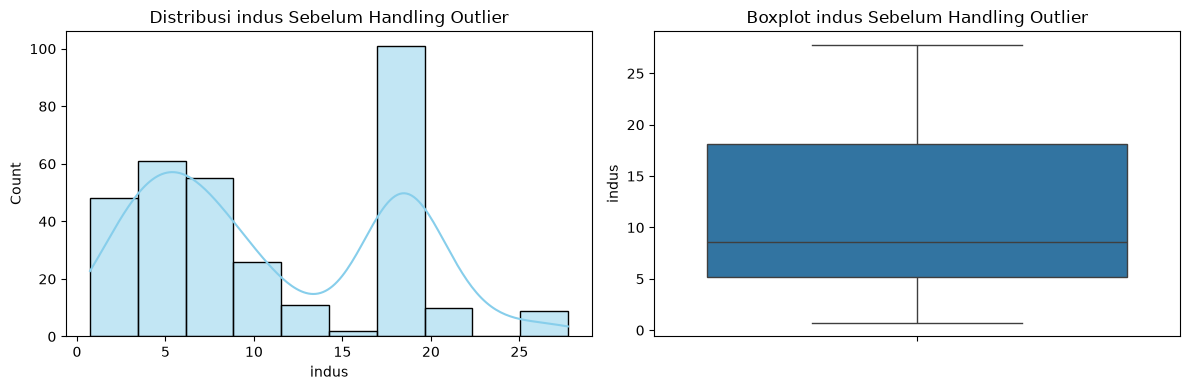

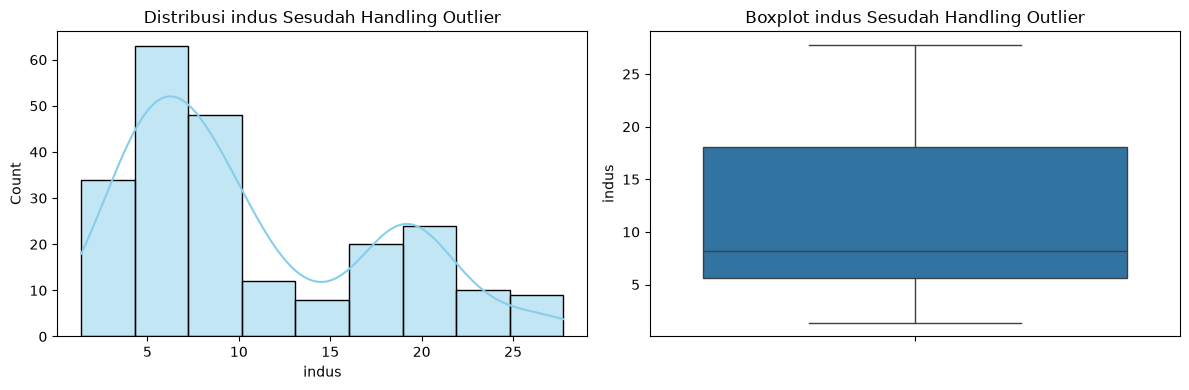

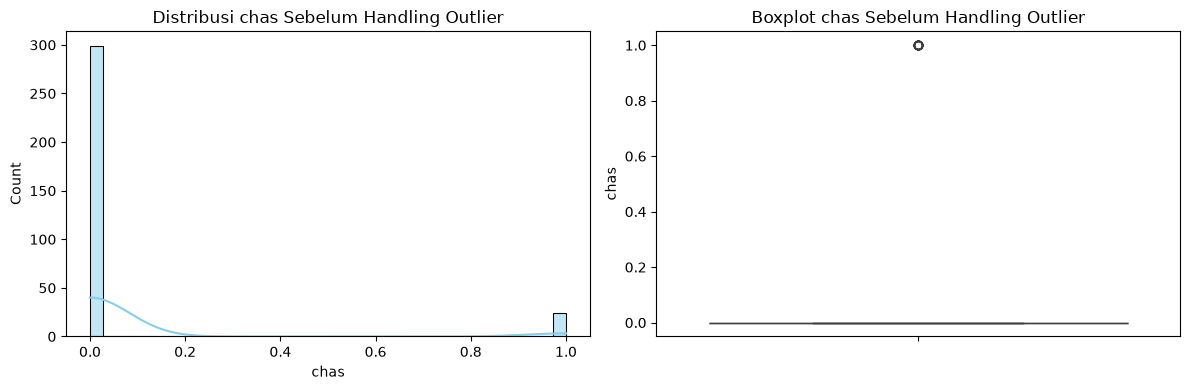

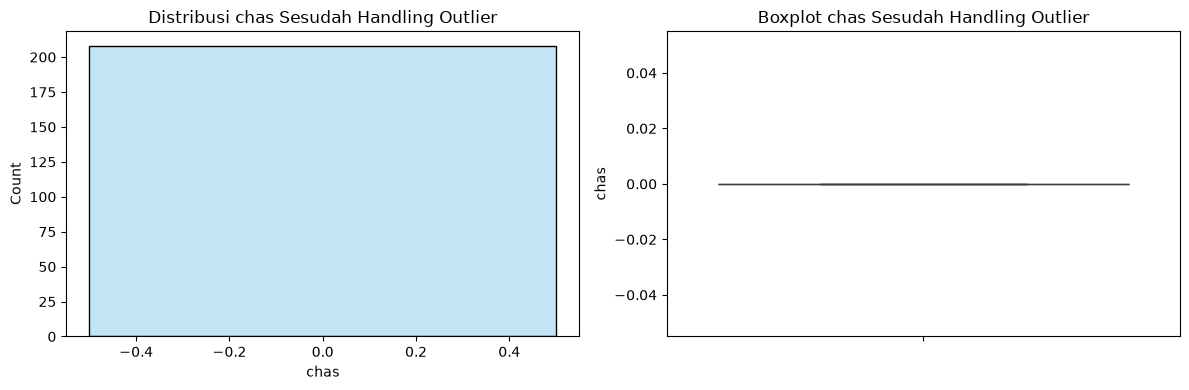

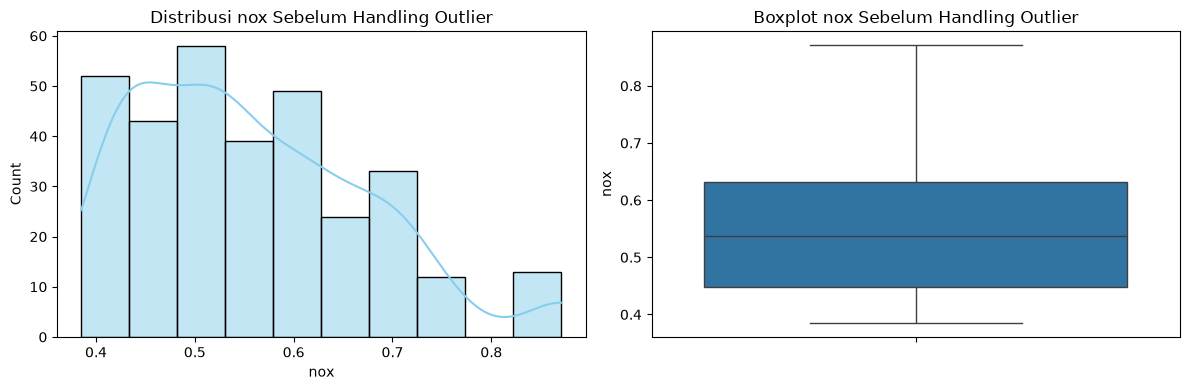

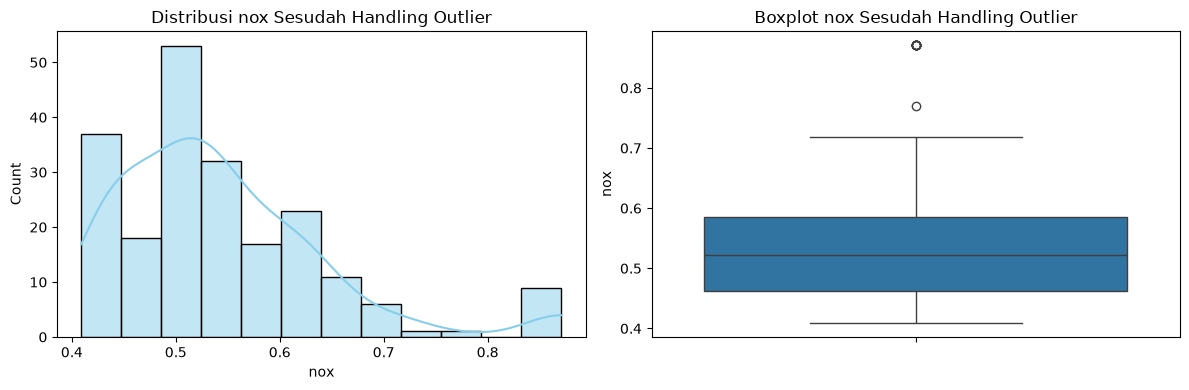

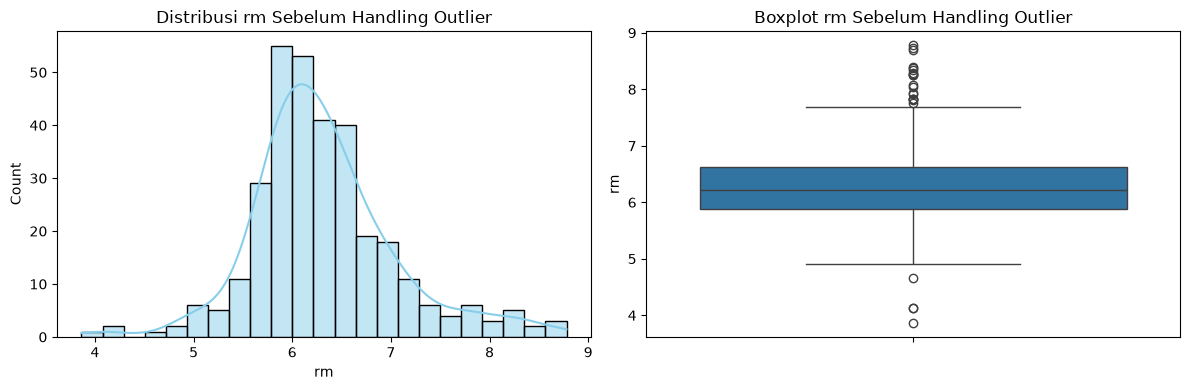

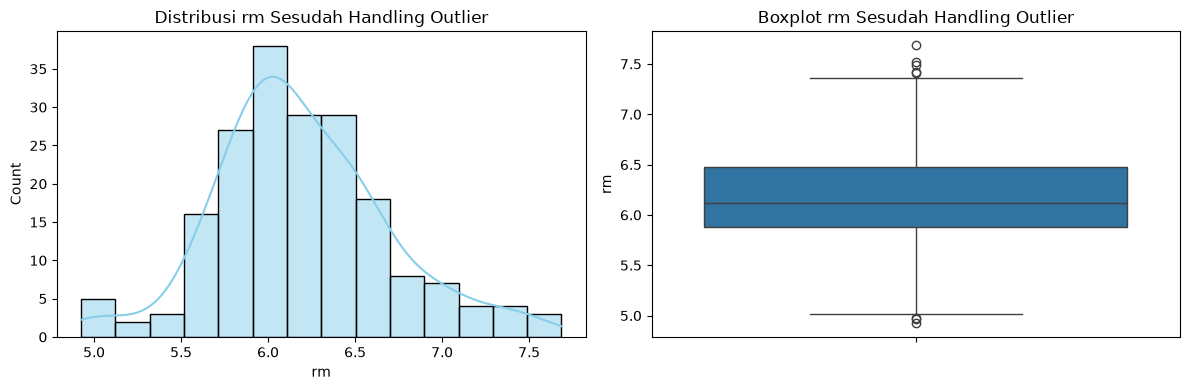

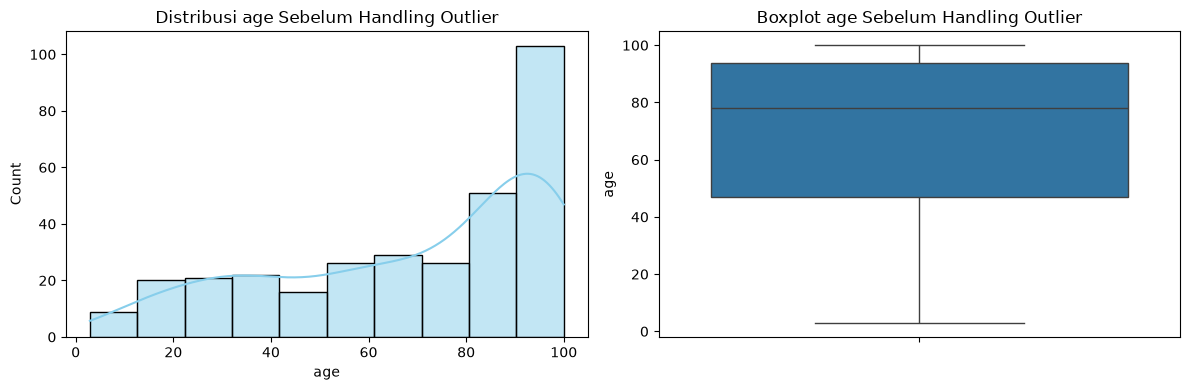

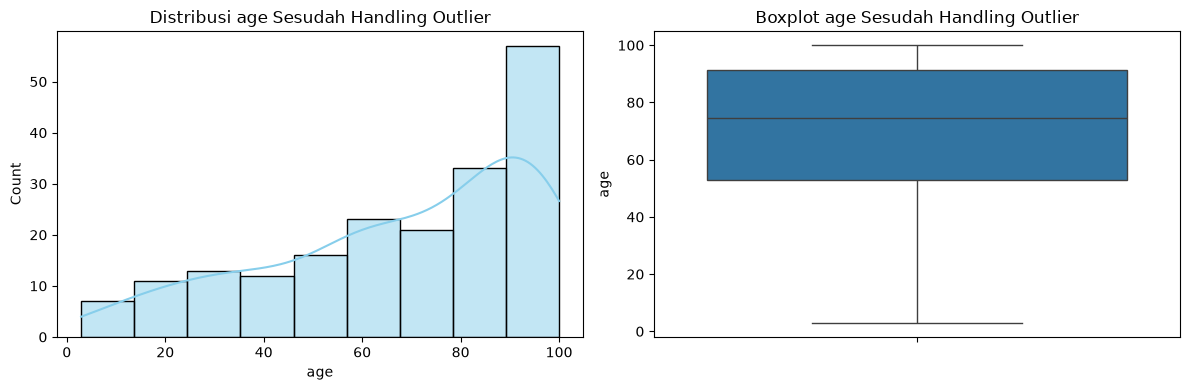

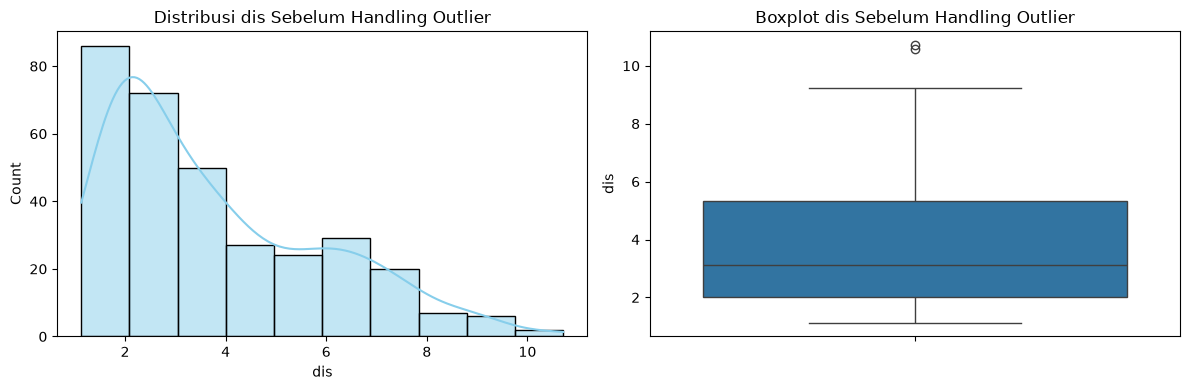

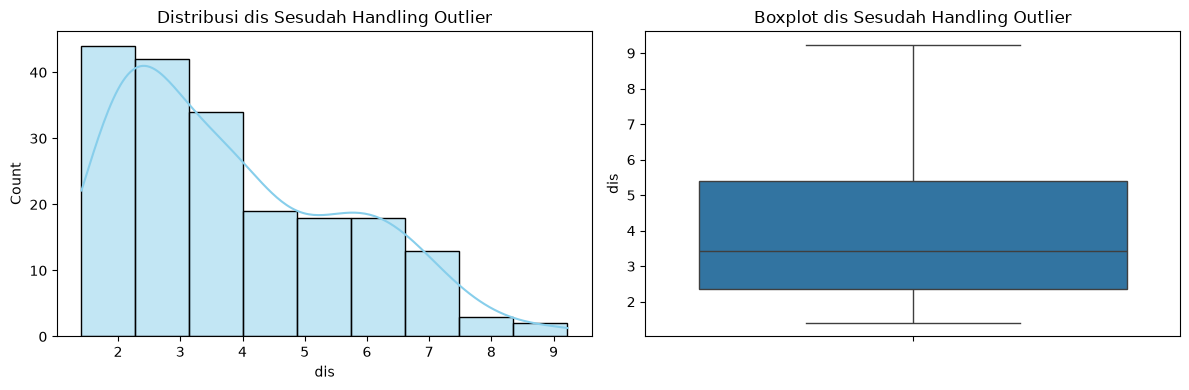

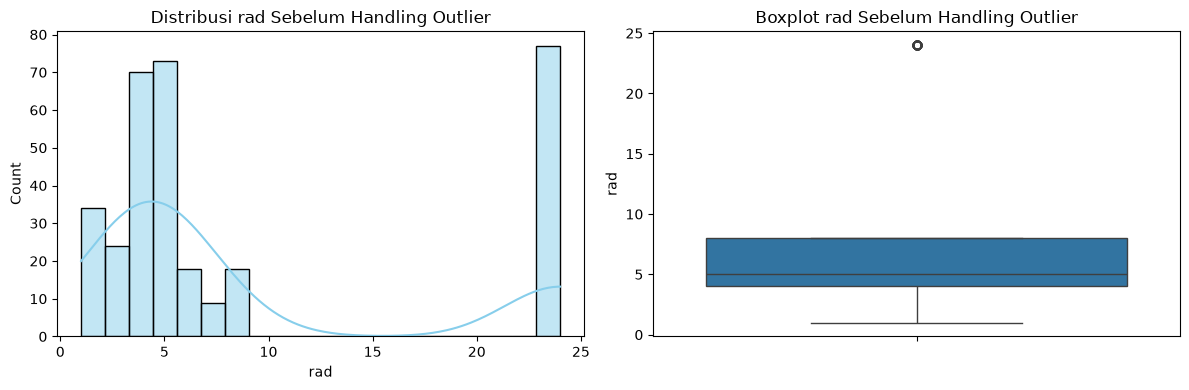

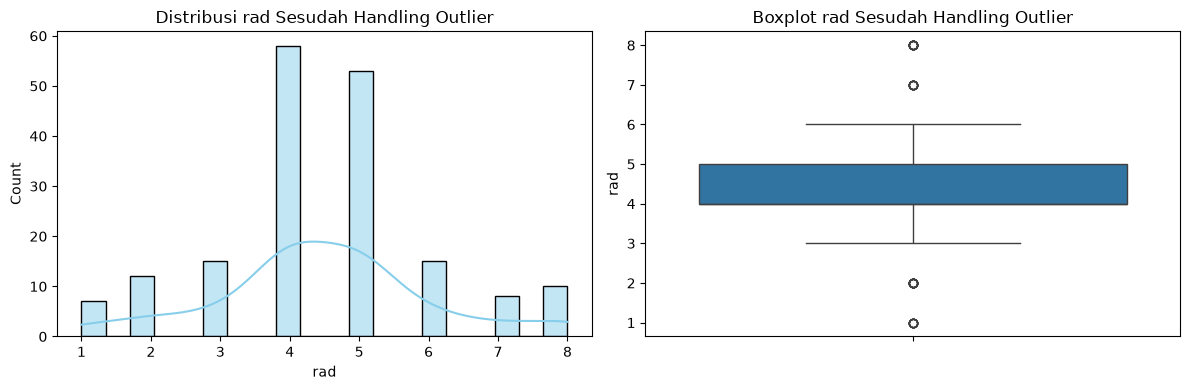

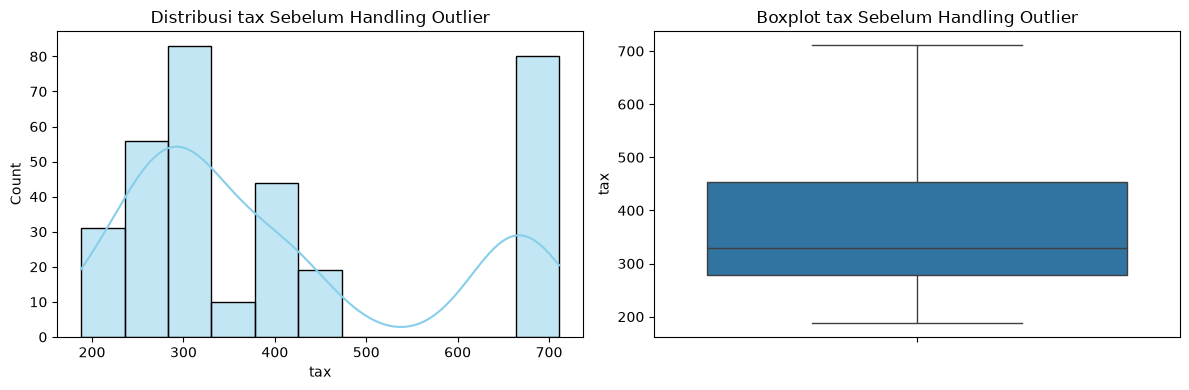

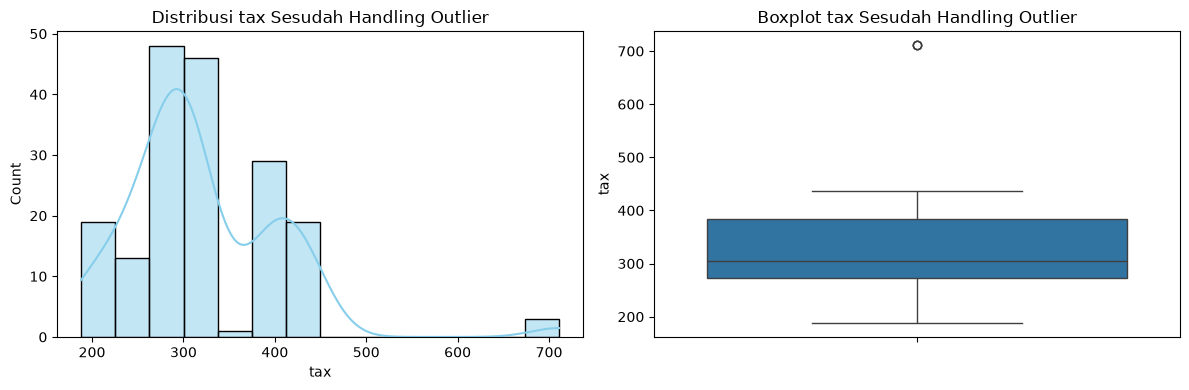

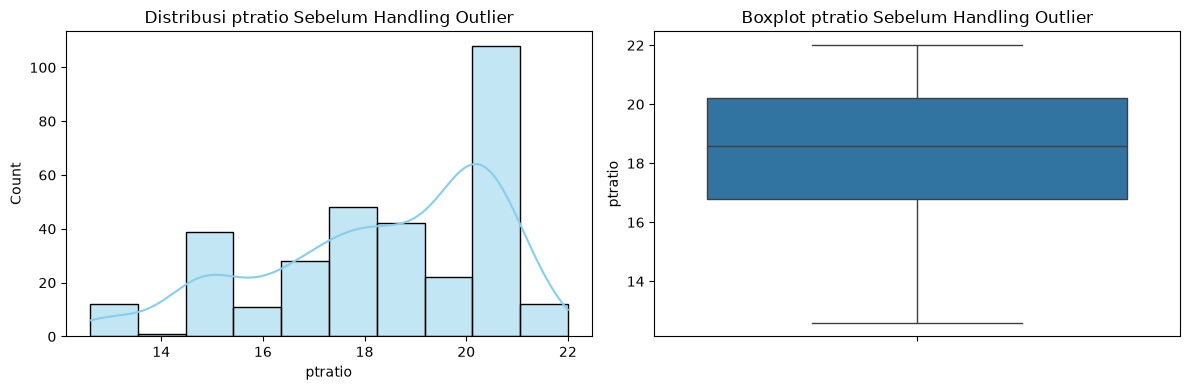

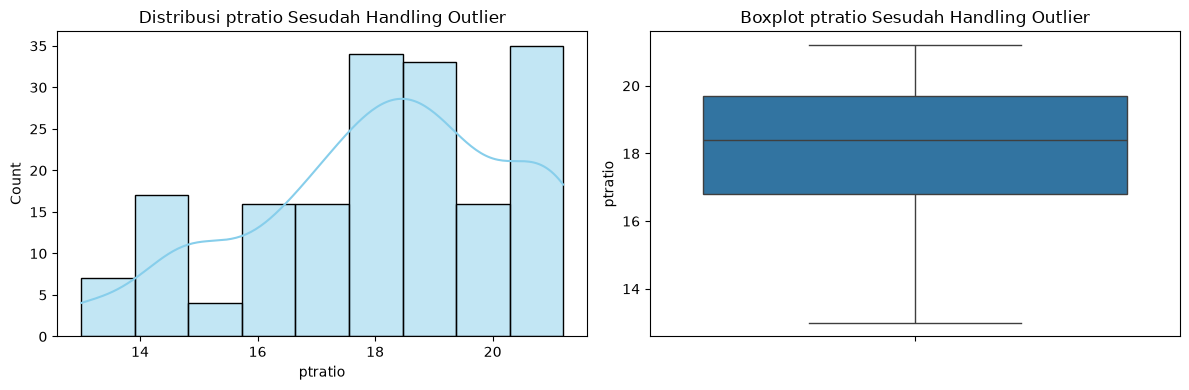

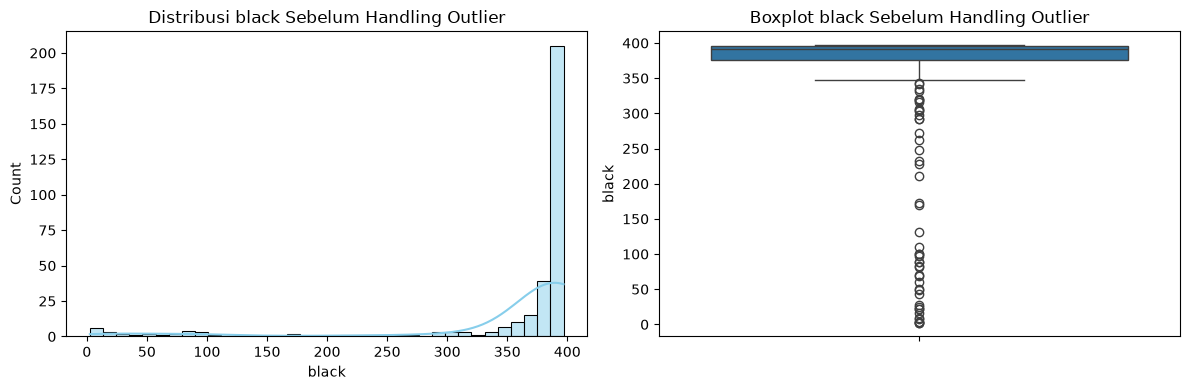

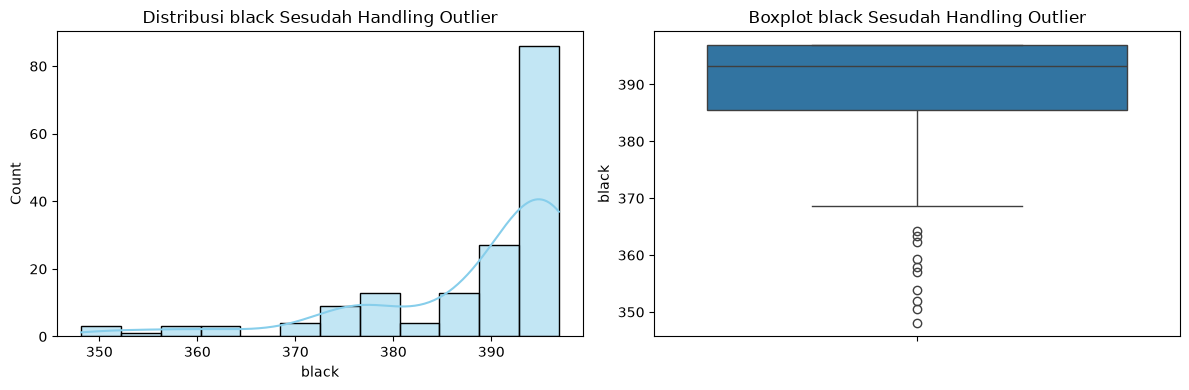

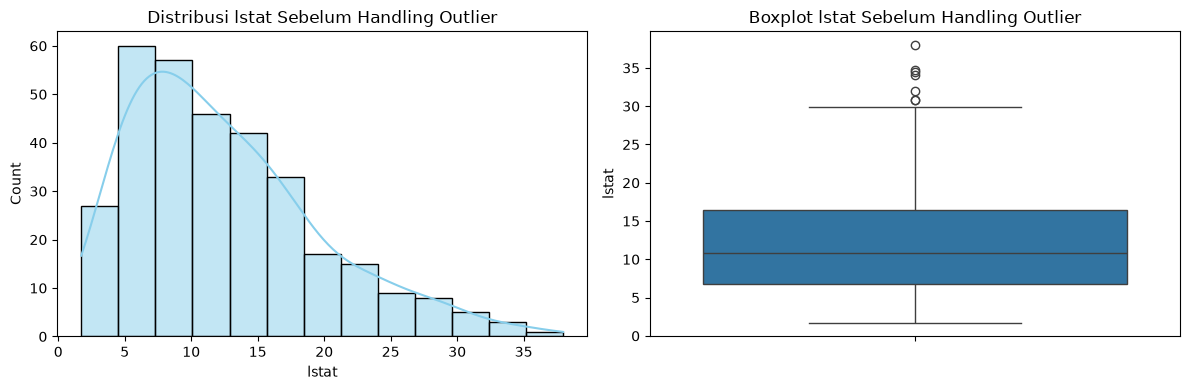

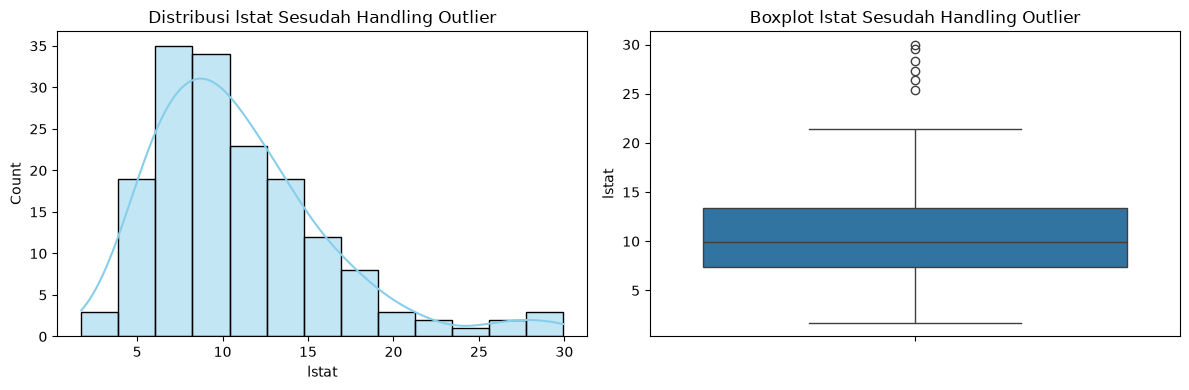

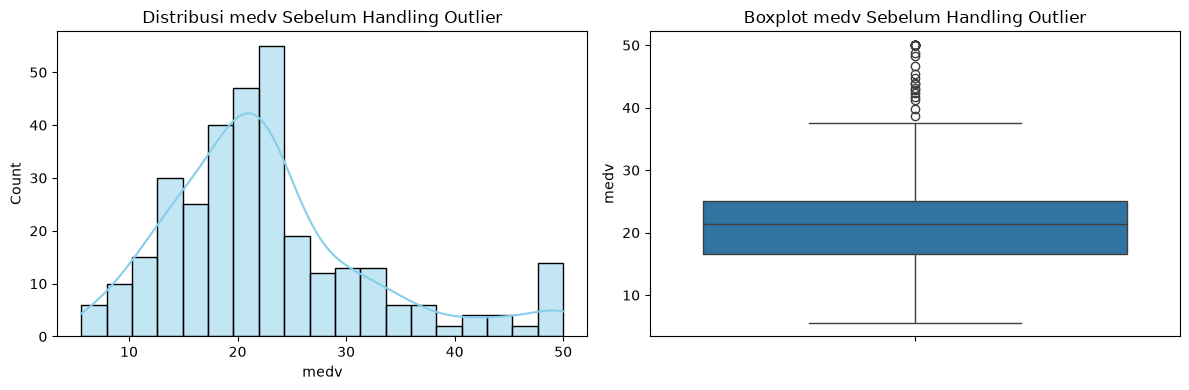

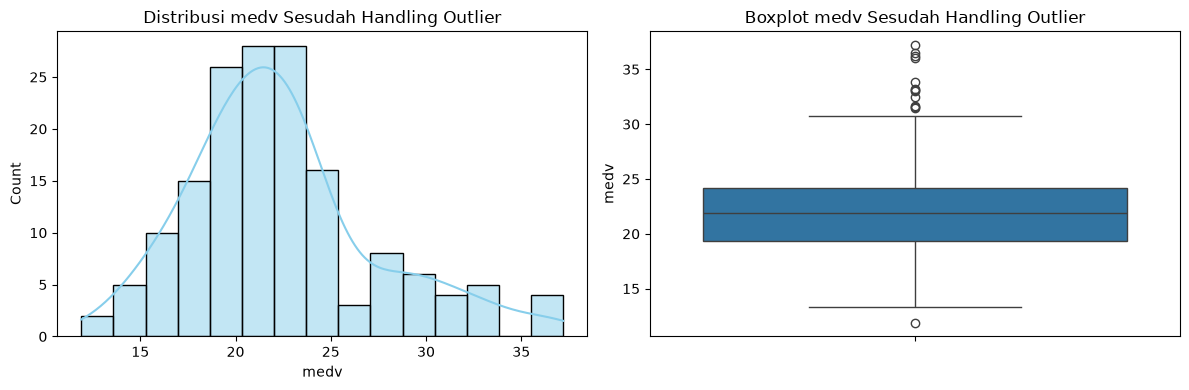

In [41]:
# Membuat Salinan "df_non_outlier"
df_nonoutlier_afterhandling = df_non_outlier.copy()

# Iterasi
for kolom in train_data.columns:
    # Handling Outlier dengan IQR
    IQR = df_non_outlier[kolom].quantile(0.75) - df_non_outlier[kolom].quantile(0.25)
    lower_boundary = df_non_outlier[kolom].quantile(0.25) - (IQR * 1.5)
    upper_boundary = df_non_outlier[kolom].quantile(0.75) + (IQR * 1.5)

    # Data setelah Handling Outlier
    df_nonoutlier_afterhandling = df_nonoutlier_afterhandling[(df_nonoutlier_afterhandling[kolom] <= upper_boundary) & (df_nonoutlier_afterhandling[kolom] >= lower_boundary)]

    # Visualisasi Data Sebelum Handling Outlier
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df_non_outlier[kolom], kde=True, ax=axes[0], color="skyblue")
    axes[0].set_title(f'Distribusi {kolom} Sebelum Handling Outlier')
    sns.boxplot(data=df_non_outlier, y=kolom, ax=axes[1])
    axes[1].set_title(f"Boxplot {kolom} Sebelum Handling Outlier")
    plt.tight_layout()
    plt.show()

    # Visualisasi Data Setelah Handling Outlier
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df_nonoutlier_afterhandling[kolom], kde=True, ax=axes[0], color="skyblue")
    axes[0].set_title(f'Distribusi {kolom} Sesudah Handling Outlier')
    sns.boxplot(data=df_nonoutlier_afterhandling, y=kolom, ax=axes[1])
    axes[1].set_title(f"Boxplot {kolom} Sesudah Handling Outlier")
    plt.tight_layout()
    plt.show()

# Exploratory Data Analysis

In [43]:
# Identifikasi Statistik Deskriptif pada Data Training
train_data.describe().round(3)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000,323.000
mean,3.491,11.570,11.086,0.074,0.557,6.318,68.854,3.776,9.077,400.793,18.307,354.294,12.500,22.786
std,8.572,23.573,6.969,0.263,0.118,0.732,27.972,2.129,8.493,164.342,2.241,95.470,7.152,9.545
min,0.009,0.000,0.740,0.000,0.385,3.863,2.900,1.130,1.000,188.000,12.600,2.520,1.730,5.600
25%,0.080,0.000,5.160,0.000,0.448,5.888,46.950,2.031,4.000,279.000,16.800,375.720,6.825,16.650
50%,0.269,0.000,8.560,0.000,0.538,6.209,78.100,3.112,5.000,329.000,18.600,391.270,10.870,21.400
75%,2.685,15.000,18.100,0.000,0.631,6.630,93.950,5.344,8.000,453.000,20.200,396.260,16.395,25.050
max,88.976,100.000,27.740,1.000,0.871,8.780,100.000,10.710,24.000,711.000,22.000,396.900,37.970,50.000


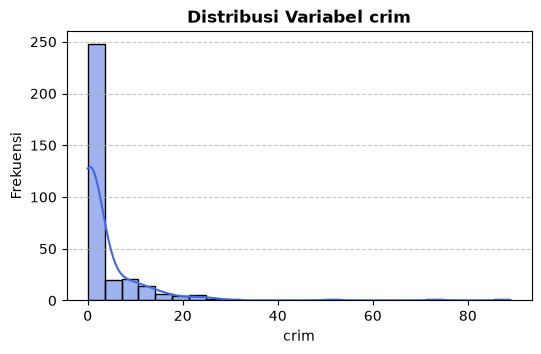

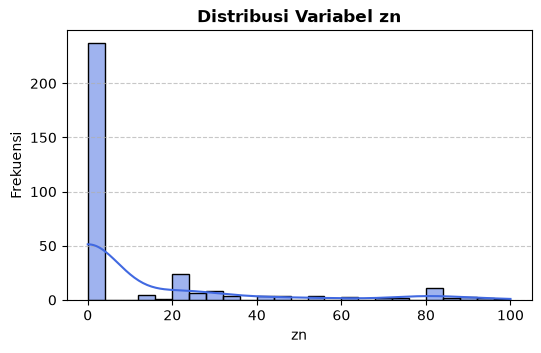

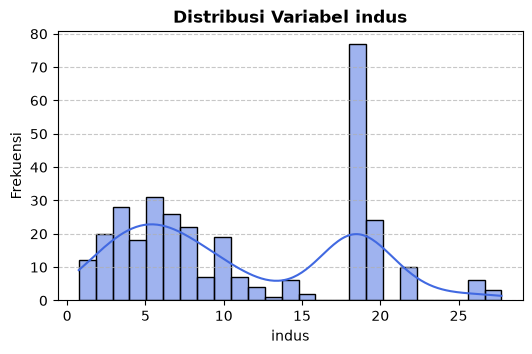

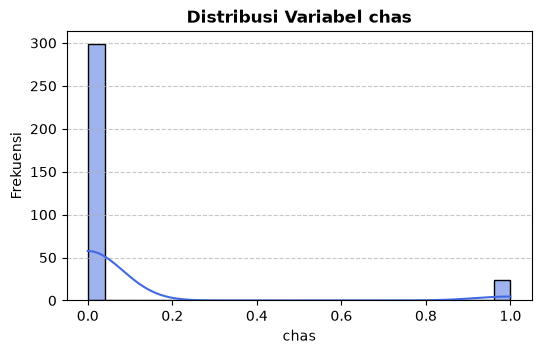

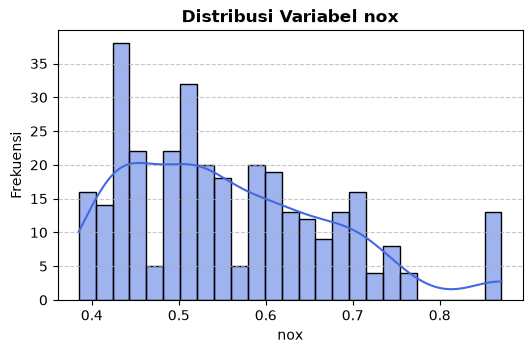

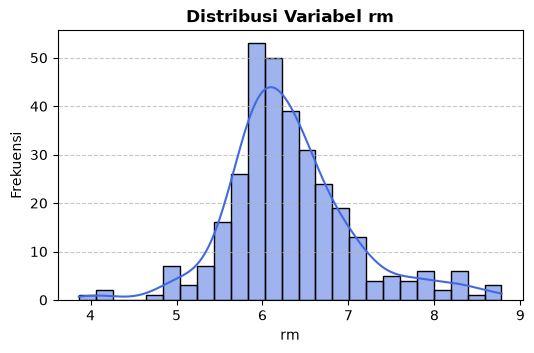

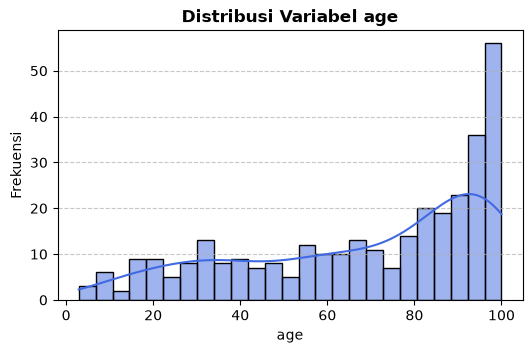

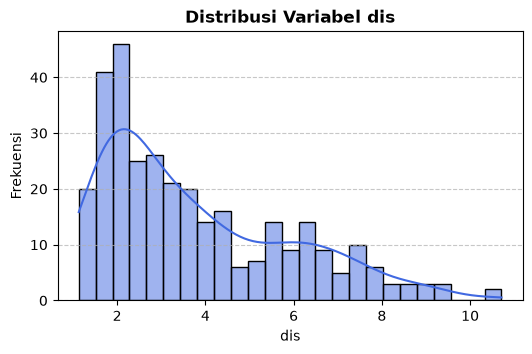

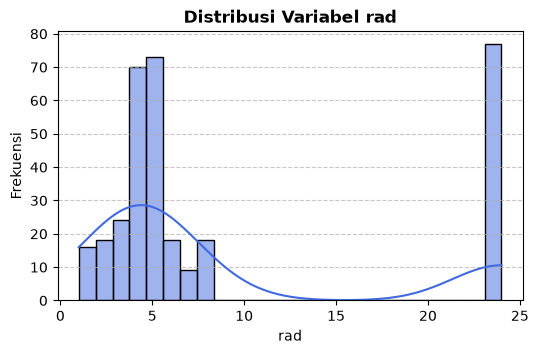

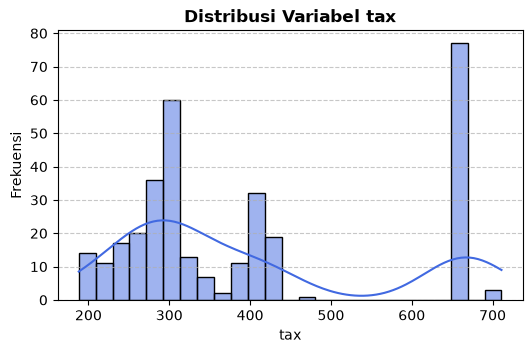

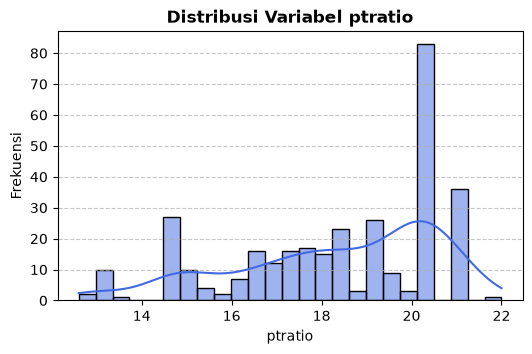

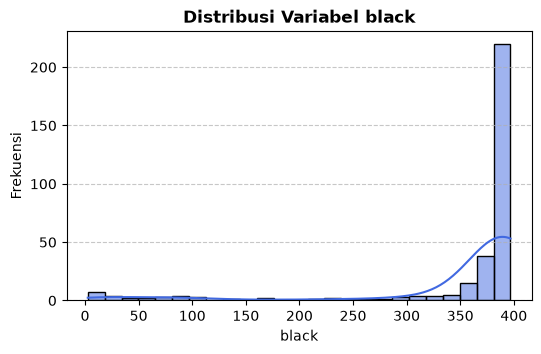

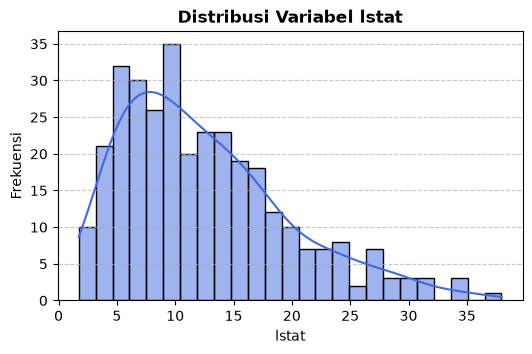

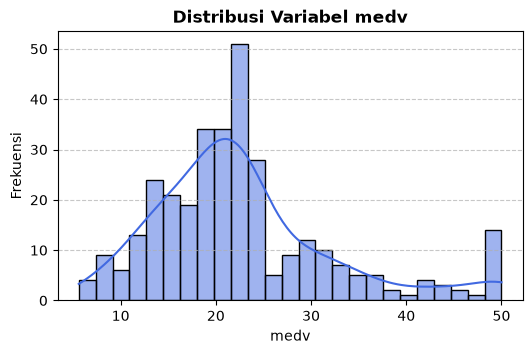

In [44]:
# Menampilkan Visualisasi Distribusi Masing-Masing Variabel Pada Data Train
for col in train_data.columns:
    plt.figure(figsize=(6, 3.5))

    # Membuat histogram dan kurva tren (KDE)
    sns.histplot(data=train_data, x=col, kde=True, color='royalblue', bins=25)

    plt.title(f'Distribusi Variabel {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.show()

In [45]:
# Menghitung VIF Scores
X = add_constant(X_train)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df.round(3)

,feature,vif_score
1,crim,1.751
2,zn,2.473
3,indus,3.742
4,chas,1.110
5,nox,4.586
6,rm,1.972
7,age,3.127
8,dis,4.390
9,rad,7.182
10,tax,8.268


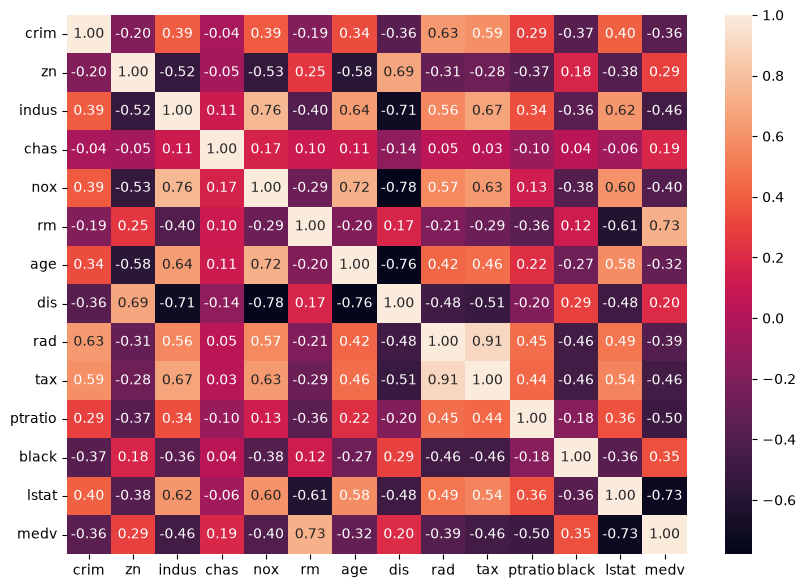

In [46]:
# Membuat Heatmap Correlation Matrix untuk Data Training
corr = train_data.corr()

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

In [47]:
# Menghapus Kolom "rad"
X_train_norad = X_train.drop('rad', axis=1)
X_val_norad = X_val.drop('rad', axis=1)
X_test_norad = X_test.drop('rad', axis=1)

In [48]:
# Menghitung Kembali VIF Scores
X = add_constant(X_train_norad)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df.round(3)

,feature,vif_score
1,crim,1.615
2,zn,2.415
3,indus,3.500
4,chas,1.098
5,nox,4.552
6,rm,1.923
7,age,3.120
8,dis,4.390
9,tax,3.191
10,ptratio,1.805


# Training Model

In [51]:
# Melakukan Scaling Feature Pada Data Training, Validation, dan Testing
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_norad)
X_val_scaled = scaler.transform(X_val_norad)
X_test_scaled = scaler.transform(X_test_norad)

## Ridge Regression

In [53]:
# Menentukan Alpha yang Digunakan
alphas = [0.01, 0.1, 1, 10]

# Membuat Tempat Penyimpanan Hasil Training Model Ridge Regression
ridge_models = {}

# Melatih Model Ridge Regression untuk Setiap Alpha
X_train_ridge = X_train_scaled
y_train_ridge = y_train.to_numpy()
y_train_ridge = y_train_ridge.reshape(len(y_train_ridge),)

for alpha in alphas:
    model_name = f'ridge_reg_{alpha}'
    ridge_models[model_name] = Ridge(alpha=alpha, random_state=42)
    ridge_models[model_name].fit(X_train_ridge, y_train_ridge)

## Lasso Regression

In [54]:
# Menentukan Alpha yang Digunakan
alphas = [0.01, 0.1, 1, 10]

# Membuat Tempat Penyimpanan Hasil Training Model Lasso Regression
lasso_models = {}

# Melatih Model Lasso Regression untuk Setiap Alpha
X_train_lasso = X_train_scaled
y_train_lasso = y_train.to_numpy()
y_train_lasso = y_train_lasso.reshape(len(y_train_lasso),)

for alpha in alphas:
    model_name = f'lasso_reg_{alpha}'
    lasso_models[model_name] = Lasso(alpha=alpha, random_state=42, max_iter=10000)
    lasso_models[model_name].fit(X_train_lasso, y_train_lasso)

# Evaluate Model

## With Data Validation

### Ridge Regression

In [55]:
# Evaluasi Model Ridge Regression pada Data Validation
X_val_ridge = X_val_scaled
y_val_ridge = y_val.to_numpy()
y_val_ridge = y_val_ridge.reshape(len(y_val_ridge),)

for alpha in alphas:
    model_name = f'ridge_reg_{alpha}'
    y_predict_validation = ridge_models[model_name].predict(X_val_ridge)
    rmse = np.sqrt(mean_squared_error(y_val_ridge, y_predict_validation))
    print(f'RMSE dari Model Ridge Regression dengan Alpha Sebesar {alpha} adalah {rmse:.3f}')

RMSE dari Model Ridge Regression dengan Alpha Sebesar 0.01 adalah 4.962
RMSE dari Model Ridge Regression dengan Alpha Sebesar 0.1 adalah 4.962
RMSE dari Model Ridge Regression dengan Alpha Sebesar 1 adalah 4.957
RMSE dari Model Ridge Regression dengan Alpha Sebesar 10 adalah 4.925


In [56]:
# Identifikasi Koefisien Setiap Feature Pada Model Ridge Regression Dengan Alpha Terbaik
ridge_best = Ridge(alpha=10, random_state=42)
ridge_best.fit(X_train_ridge, y_train_ridge)

coef_ridge = pd.DataFrame({
    'feature':['intercept'] + X_train_norad.columns.tolist(),
    'coefficient':[ridge_best.intercept_] + list(ridge_best.coef_)
})

coef_ridge.round(3)

,feature,coefficient
0,intercept,22.786
1,crim,-0.622
2,zn,0.517
3,indus,-0.089
4,chas,0.857
5,nox,-1.775
6,rm,3.738
7,age,-0.111
8,dis,-2.810
9,tax,0.013


### Lasso Regression

In [57]:
# Evaluasi Model Lasso Regression pada Data Validation
X_val_lasso = X_val_scaled
y_val_lasso = y_val.to_numpy()
y_val_lasso = y_val_lasso.reshape(len(y_val_lasso),)

for alpha in alphas:
    model_name = f'lasso_reg_{alpha}'
    y_predict_validation = lasso_models[model_name].predict(X_val_lasso)
    rmse = np.sqrt(mean_squared_error(y_val_lasso, y_predict_validation))
    print(f'RMSE dari Model Lasso Regression dengan Alpha Sebesar {alpha} adalah {rmse:.3f}')

RMSE dari Model Lasso Regression dengan Alpha Sebesar 0.01 adalah 4.958
RMSE dari Model Lasso Regression dengan Alpha Sebesar 0.1 adalah 4.922
RMSE dari Model Lasso Regression dengan Alpha Sebesar 1 adalah 5.201
RMSE dari Model Lasso Regression dengan Alpha Sebesar 10 adalah 8.432


In [58]:
# Identifikasi Koefisien Setiap Feature Pada Model Lasso Regression Dengan Alpha Terbaik
lasso_best = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso_best.fit(X_train_lasso, y_train_lasso)

coef_lasso = pd.DataFrame({
    'feature':['intercept'] + X_train_norad.columns.tolist(),
    'coefficient':[lasso_best.intercept_] + list(lasso_best.coef_)
})

coef_lasso.round(3)

,feature,coefficient
0,intercept,22.786
1,crim,-0.523
2,zn,0.328
3,indus,-0.000
4,chas,0.771
5,nox,-1.653
6,rm,3.790
7,age,-0.000
8,dis,-2.461
9,tax,-0.000


## With Data Testing

In [62]:
# Evaluasi Model Linear Regression pada Data Testing Menggunakan Ridge Regression Dengan Alpha Terbaik
X_test_ridge = X_test_scaled
y_test_ridge = y_test.to_numpy()
y_test_ridge = y_test_ridge.reshape(len(y_test_ridge),)

y_predict_test = ridge_best.predict(X_test_ridge)

mae = mean_absolute_error(y_test_ridge, y_predict_test)
mape = np.mean(np.abs((y_test_ridge - y_predict_test) / y_test_ridge)) * 100
rmse = np.sqrt(mean_squared_error(y_test_ridge, y_predict_test))

# Menampilkan Hasil Evaluasi Model Linear Regression pada Data Testing Menggunakan Ridge Regression Dengan Alpha Terbaik
print("\n=== Evaluasi Model Linear Regression pada Data Testing Menggunakan Ridge Regression Dengan Alpha Terbaik ===")
print(f'MAE: {mae:.3f}')
print(f'MAPE: {mape:.2f}%')
print(f'RMSE: {rmse:.3f}')


=== Evaluasi Model Linear Regression pada Data Testing Menggunakan Ridge Regression Dengan Alpha Terbaik ===
MAE: 3.283
MAPE: 17.68%
RMSE: 5.166


In [63]:
# Evaluasi Model Linear Regression pada Data Testing Menggunakan Lasso Regression Dengan Alpha Terbaik
X_test_lasso = X_test_scaled
y_test_lasso = y_test.to_numpy()
y_test_lasso = y_test_lasso.reshape(len(y_test_lasso),)

y_predict_test = lasso_best.predict(X_test_lasso)

mae = mean_absolute_error(y_test_lasso, y_predict_test)
mape = np.mean(np.abs((y_test_lasso - y_predict_test) / y_test_lasso)) * 100
rmse = np.sqrt(mean_squared_error(y_test_lasso, y_predict_test))

# Menampilkan Hasil Evaluasi Model Linear Regression pada Data Testing Menggunakan Lasso Regression Dengan Alpha Terbaik
print("\n=== Evaluasi Model Linear Regression pada Data Testing Menggunakan Lasso Regression Dengan Alpha Terbaik ===")
print(f'MAE: {mae:.3f}')
print(f'MAPE: {mape:.2f}%')
print(f'RMSE: {rmse:.3f}')


=== Evaluasi Model Linear Regression pada Data Testing Menggunakan Lasso Regression Dengan Alpha Terbaik ===
MAE: 3.288
MAPE: 17.72%
RMSE: 5.190


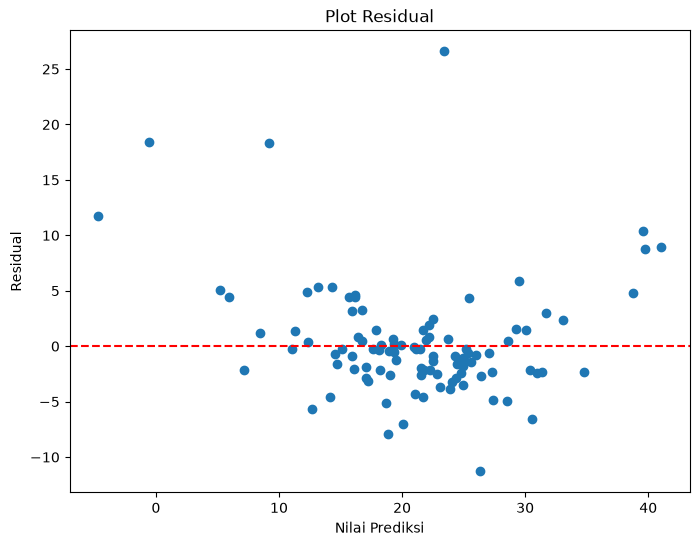

In [64]:
# Menampilkan Plot Residual
residual = y_test_ridge - y_predict_test
plt.figure(figsize=(8,6))
plt.scatter(y_predict_test, residual)
plt.xlabel('Nilai Prediksi')
plt.ylabel('Residual')
plt.title('Plot Residual')
plt.axhline(0, color='red', linestyle='--')
plt.show()